In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
import pandas as pd

df = pd.read_csv(
    r"C:\Users\DELL\Downloads\netflix dataset\netflix_titles.csv"
)

print("Netflix dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Netflix dataset loaded successfully!
Dataset shape: (8807, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [3]:
print("Dataset Information:")
df.info()

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 3.9 MB


In [4]:
missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

Missing Values in Each Column:
show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64


In [5]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

print("Missing Value Percentage:")
print(missing_percentage.round(2))

Missing Value Percentage:
show_id          0.00
type             0.00
title            0.00
director        29.91
cast             9.37
country          9.44
date_added       0.11
release_year     0.00
rating           0.05
duration         0.03
listed_in        0.00
description      0.00
dtype: float64


In [6]:
print("Total Duplicate Rows:", df.duplicated().sum())

Total Duplicate Rows: 0


In [7]:
columns_to_fill = [
    'director',
    'cast',
    'country',
    'rating'
]

for col in columns_to_fill:
    df[col] = df[col].fillna('Unknown')

print("Missing values filled successfully!")

Missing values filled successfully!


In [8]:
df = df.dropna(subset=['date_added', 'duration'])

print("Dataset shape after cleaning:", df.shape)
print("Total missing values:", df.isnull().sum().sum())

Dataset shape after cleaning: (8794, 12)
Total missing values: 0


In [9]:
df['date_added'] = pd.to_datetime(
    df['date_added'].str.strip(),
    errors='coerce'
)

print("Date conversion completed!")
print(df['date_added'].dtype)

Date conversion completed!
datetime64[us]


In [10]:
df['year_added'] = df['date_added'].dt.year

df['month_added'] = df['date_added'].dt.month_name()

print("Year and Month columns created!")
df[['title', 'date_added', 'year_added', 'month_added']].head(10)

Year and Month columns created!


,title,date_added,year_added,month_added
0,Dick Johnson Is Dead,2021-09-25,2021,September
1,Blood & Water,2021-09-24,2021,September
2,Ganglands,2021-09-24,2021,September
3,Jailbirds New Orleans,2021-09-24,2021,September
4,Kota Factory,2021-09-24,2021,September
5,Midnight Mass,2021-09-24,2021,September
6,My Little Pony: A New Generation,2021-09-24,2021,September
7,Sankofa,2021-09-24,2021,September
8,The Great British Baking Show,2021-09-24,2021,September
9,The Starling,2021-09-24,2021,September


type
Movie      6128
TV Show    2666
Name: count, dtype: int64


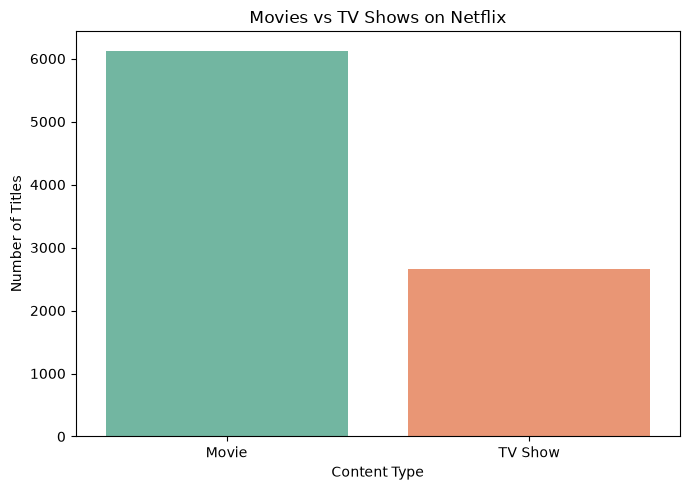

In [11]:
print(df['type'].value_counts())

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='type',
    hue='type',
    palette='Set2',
    legend=False
)

plt.title('Movies vs TV Shows on Netflix')
plt.xlabel('Content Type')
plt.ylabel('Number of Titles')
plt.tight_layout()

plt.savefig('movies_vs_tvshows.png', dpi=300)
plt.show()

In [12]:
genre_counts = df['listed_in'].str.split(', ').explode()

top_genres = genre_counts.value_counts().head(10)

print("Top 10 Netflix Genres:")
print(top_genres)

Top 10 Netflix Genres:
listed_in
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1350
Documentaries                869
Action & Adventure           859
TV Dramas                    762
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


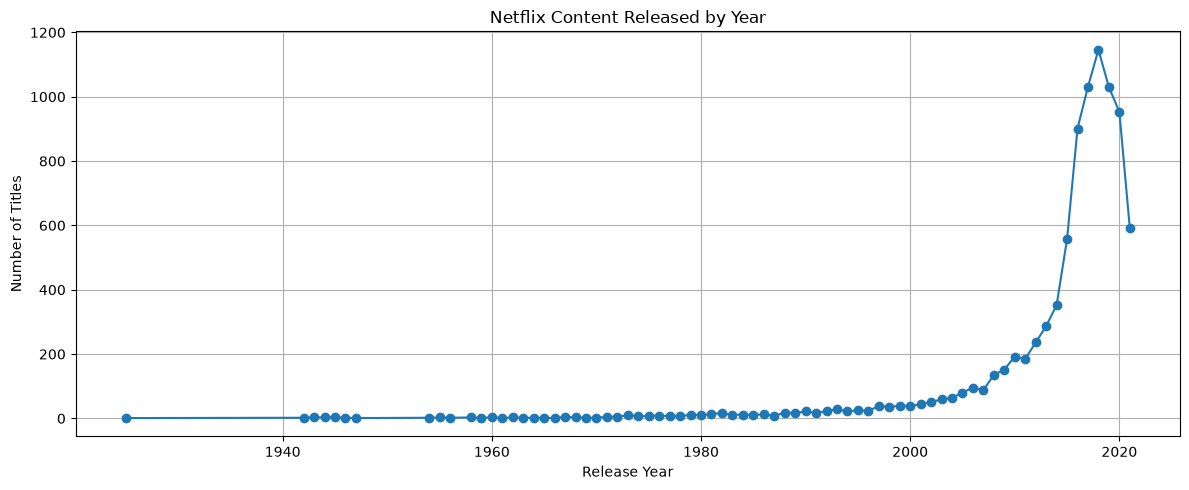

In [13]:
year_counts = df['release_year'].value_counts().sort_index()

plt.figure(figsize=(12, 5))

plt.plot(
    year_counts.index,
    year_counts.values,
    marker='o'
)

plt.title('Netflix Content Released by Year')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')
plt.grid(True)
plt.tight_layout()

plt.savefig('content_by_release_year.png', dpi=300)
plt.show()

In [14]:
country_counts = df['country'].str.split(', ').explode()

country_counts = country_counts[
    country_counts != 'Unknown'
]

top_countries = country_counts.value_counts().head(10)

print("Top 10 Countries:")
print(top_countries)

Top 10 Countries:
country
United States     3680
India             1046
United Kingdom     803
Canada             445
France             393
Japan              317
Spain              232
South Korea        231
Germany            226
Mexico             169
Name: count, dtype: int64


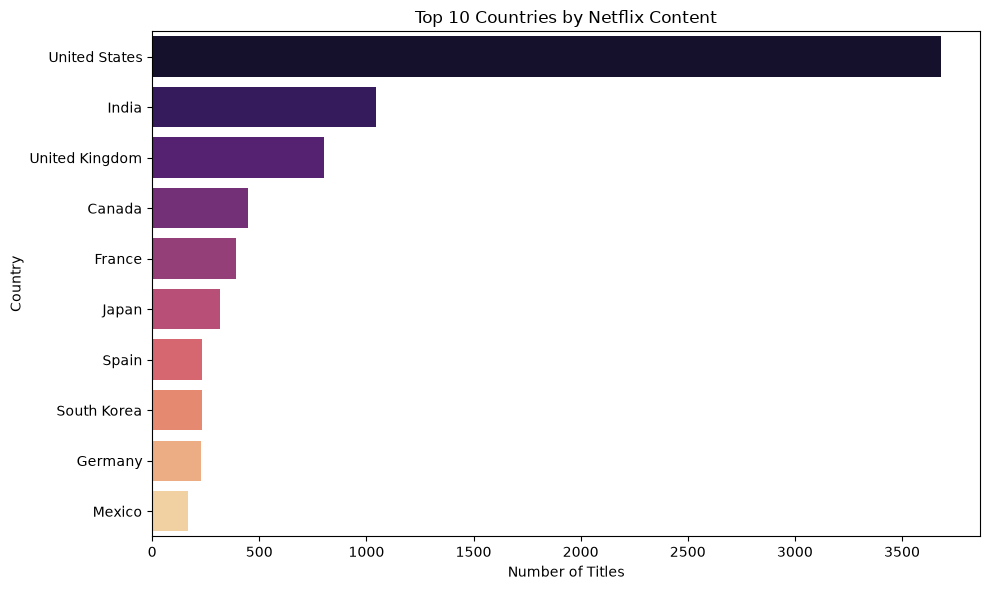

In [15]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_countries.values,
    y=top_countries.index,
    hue=top_countries.index,
    palette='magma',
    legend=False
)

plt.title('Top 10 Countries by Netflix Content')
plt.xlabel('Number of Titles')
plt.ylabel('Country')
plt.tight_layout()

plt.savefig('top_10_countries.png', dpi=300)
plt.show()

In [16]:
rating_counts = df['rating'].value_counts().head(10)

print("Top 10 Content Ratings:")
print(rating_counts)

Top 10 Content Ratings:
rating
TV-MA    3205
TV-14    2157
TV-PG     861
R         799
PG-13     490
TV-Y7     333
TV-Y      306
PG        287
TV-G      220
NR         79
Name: count, dtype: int64


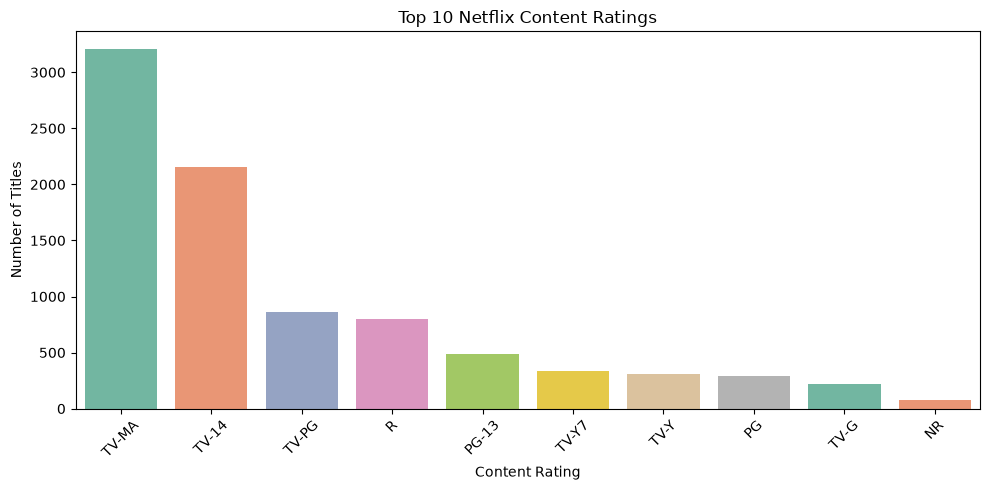

In [17]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=rating_counts.index,
    y=rating_counts.values,
    hue=rating_counts.index,
    palette='Set2',
    legend=False
)

plt.title('Top 10 Netflix Content Ratings')
plt.xlabel('Content Rating')
plt.ylabel('Number of Titles')
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig('content_ratings.png', dpi=300)
plt.show()

In [18]:
numeric_df = df.select_dtypes(include='number')

correlation = numeric_df.corr()

print(correlation)

              release_year  year_added
release_year      1.000000    0.111548
year_added        0.111548    1.000000


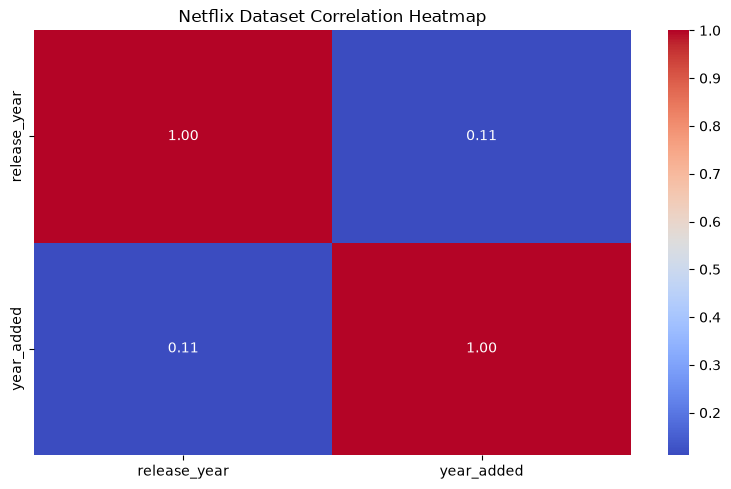

In [19]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Netflix Dataset Correlation Heatmap')
plt.tight_layout()

plt.savefig('correlation_heatmap.png', dpi=300)
plt.show()

In [20]:
movies = df[df['type'] == 'Movie'].copy()

movies['duration_minutes'] = (
    movies['duration']
    .str.replace(' min', '', regex=False)
    .astype(int)
)

print("Movie Duration Statistics:")
print(movies['duration_minutes'].describe())

Movie Duration Statistics:
count    6128.000000
mean       99.577187
std        28.290593
min         3.000000
25%        87.000000
50%        98.000000
75%       114.000000
max       312.000000
Name: duration_minutes, dtype: float64


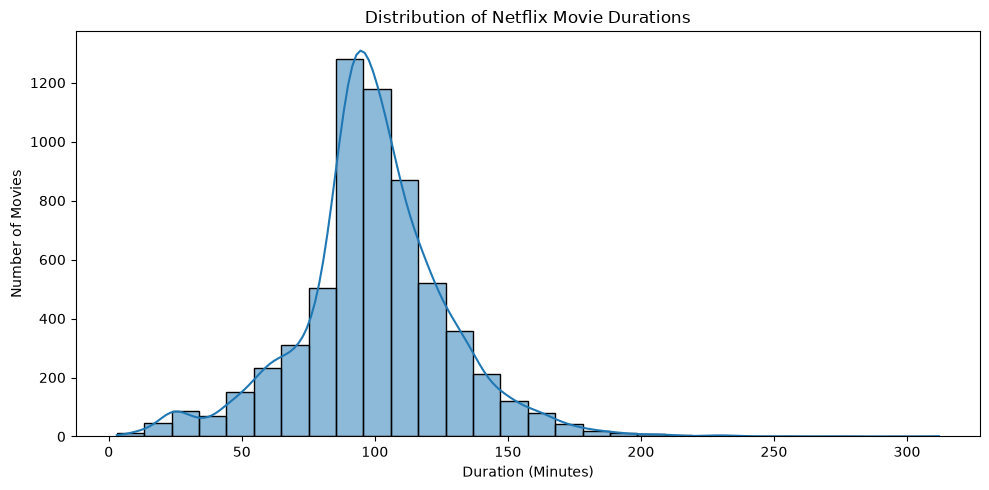

In [21]:
plt.figure(figsize=(10, 5))

sns.histplot(
    movies['duration_minutes'],
    bins=30,
    kde=True
)

plt.title('Distribution of Netflix Movie Durations')
plt.xlabel('Duration (Minutes)')
plt.ylabel('Number of Movies')
plt.tight_layout()

plt.savefig('movie_duration_distribution.png', dpi=300)
plt.show()

In [22]:
tv_shows = df[df['type'] == 'TV Show'].copy()

tv_shows['seasons'] = (
    tv_shows['duration']
    .str.replace(' Seasons', '', regex=False)
    .str.replace(' Season', '', regex=False)
    .astype(int)
)

print("TV Show Season Distribution:")
print(tv_shows['seasons'].value_counts().sort_index())

TV Show Season Distribution:
seasons
1     1793
2      421
3      198
4       94
5       64
6       33
7       23
8       17
9        9
10       6
11       1
12       2
13       2
15       2
17       1
Name: count, dtype: int64


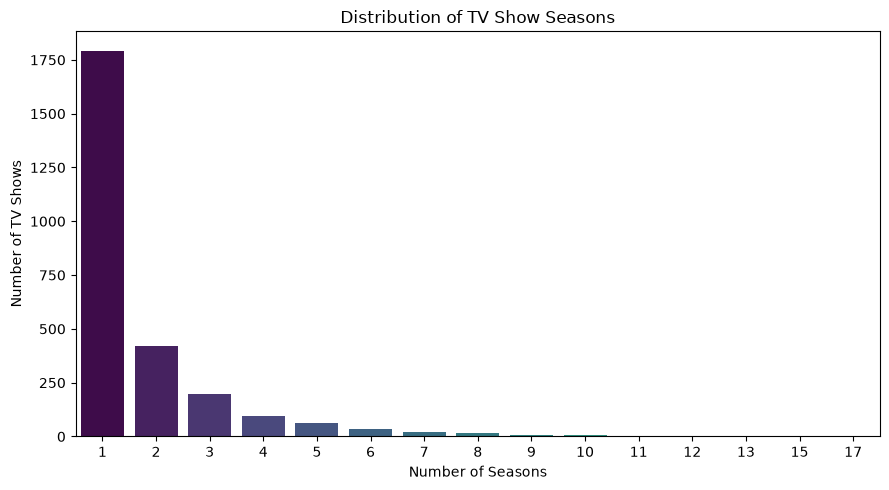

In [23]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=tv_shows,
    x='seasons',
    hue='seasons',
    palette='viridis',
    legend=False
)

plt.title('Distribution of TV Show Seasons')
plt.xlabel('Number of Seasons')
plt.ylabel('Number of TV Shows')
plt.tight_layout()

plt.savefig('tv_show_seasons.png', dpi=300)
plt.show()

In [24]:
tv_shows = df[df['type'] == 'TV Show'].copy()

tv_shows['seasons'] = (
    tv_shows['duration']
    .str.replace(' Seasons', '', regex=False)
    .str.replace(' Season', '', regex=False)
    .astype(int)
)

print("TV Show Season Distribution:")
print(tv_shows['seasons'].value_counts().sort_index())

TV Show Season Distribution:
seasons
1     1793
2      421
3      198
4       94
5       64
6       33
7       23
8       17
9        9
10       6
11       1
12       2
13       2
15       2
17       1
Name: count, dtype: int64


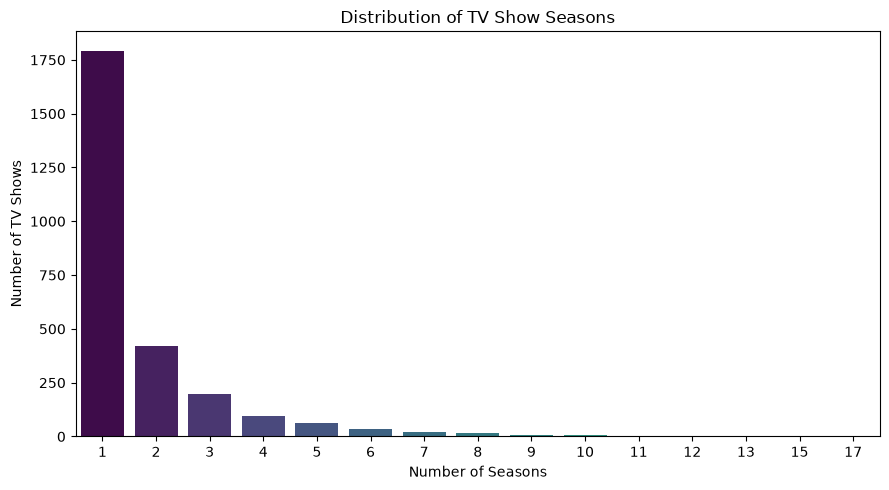

In [25]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=tv_shows,
    x='seasons',
    hue='seasons',
    palette='viridis',
    legend=False
)

plt.title('Distribution of TV Show Seasons')
plt.xlabel('Number of Seasons')
plt.ylabel('Number of TV Shows')
plt.tight_layout()

plt.savefig('tv_show_seasons.png', dpi=300)
plt.show()

In [26]:
year_added_counts = df['year_added'].value_counts().sort_index()

print("Netflix Content Added by Year:")
print(year_added_counts)

Netflix Content Added by Year:
year_added
2008       2
2009       2
2010       1
2011      13
2012       3
2013      11
2014      24
2015      82
2016     427
2017    1187
2018    1649
2019    2016
2020    1879
2021    1498
Name: count, dtype: int64


In [27]:
year_added_counts = df['year_added'].value_counts().sort_index()

print("Netflix Content Added by Year:")
print(year_added_counts)

Netflix Content Added by Year:
year_added
2008       2
2009       2
2010       1
2011      13
2012       3
2013      11
2014      24
2015      82
2016     427
2017    1187
2018    1649
2019    2016
2020    1879
2021    1498
Name: count, dtype: int64


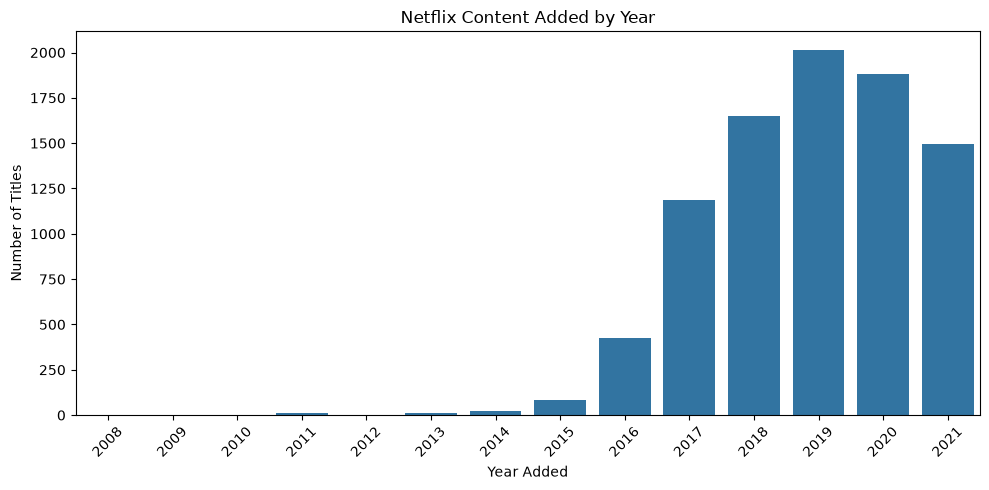

In [28]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=year_added_counts.index,
    y=year_added_counts.values
)

plt.title('Netflix Content Added by Year')
plt.xlabel('Year Added')
plt.ylabel('Number of Titles')
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig('content_added_by_year.png', dpi=300)
plt.show()

In [29]:
content_by_type_year = pd.crosstab(
    df['year_added'],
    df['type']
)

print(content_by_type_year)

type        Movie  TV Show
year_added                
2008            1        1
2009            2        0
2010            1        0
2011           13        0
2012            3        0
2013            6        5
2014           19        5
2015           56       26
2016          251      176
2017          838      349
2018         1237      412
2019         1424      592
2020         1284      595
2021          993      505


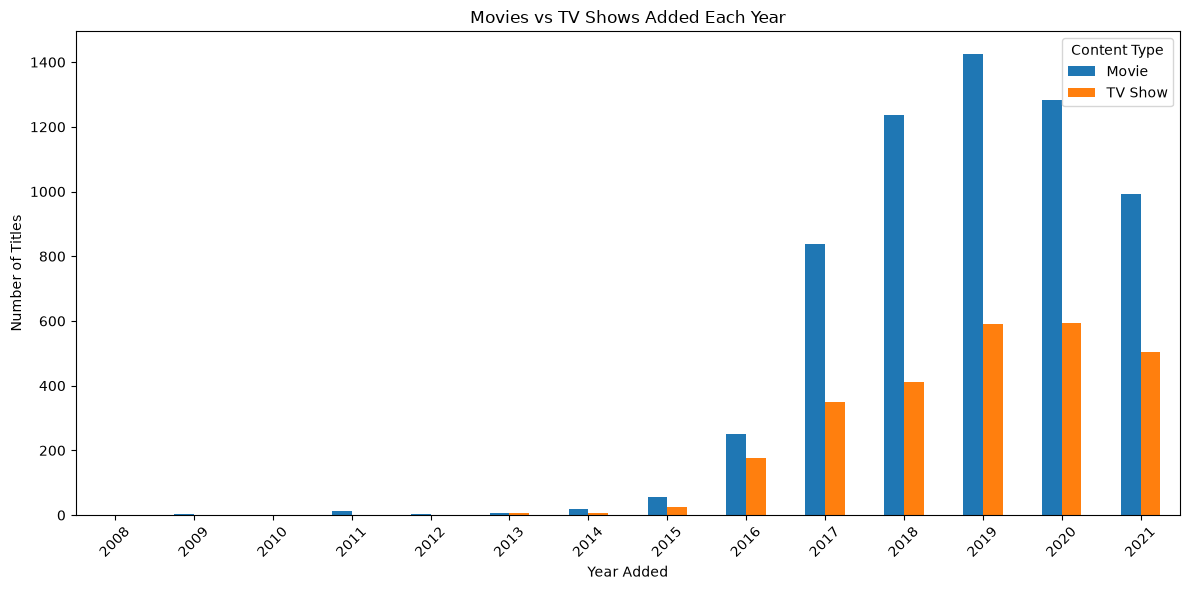

In [30]:
content_by_type_year.plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Movies vs TV Shows Added Each Year')
plt.xlabel('Year Added')
plt.ylabel('Number of Titles')
plt.legend(title='Content Type')
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig('movies_tvshows_by_year.png', dpi=300)
plt.show()

In [31]:
print("========== NETFLIX EDA KEY INSIGHTS ==========")

print("1. Total Netflix Titles:", len(df))

print("\n2. Content Type Distribution:")
print(df['type'].value_counts())

print("\n3. Top 5 Genres:")
print(top_genres.head(5))

print("\n4. Top 5 Countries:")
print(top_countries.head(5))

print("\n5. Top 5 Content Ratings:")
print(rating_counts.head(5))

print("\n6. Most Common Release Year:")
print(df['release_year'].mode()[0])

print("\n7. Most Common Year Added:")
print(df['year_added'].mode()[0])

print("\n========== EDA COMPLETED ==========")

========== NETFLIX EDA KEY INSIGHTS ==========
1. Total Netflix Titles: 8794

2. Content Type Distribution:
type
Movie      6128
TV Show    2666
Name: count, dtype: int64

3. Top 5 Genres:
listed_in
International Movies      2752
Dramas                    2427
Comedies                  1674
International TV Shows    1350
Documentaries              869
Name: count, dtype: int64

4. Top 5 Countries:
country
United States     3680
India             1046
United Kingdom     803
Canada             445
France             393
Name: count, dtype: int64

5. Top 5 Content Ratings:
rating
TV-MA    3205
TV-14    2157
TV-PG     861
R         799
PG-13     490
Name: count, dtype: int64

6. Most Common Release Year:
2018

7. Most Common Year Added:
2019

========== EDA COMPLETED ==========


In [32]:
df.to_csv("netflix_cleaned_eda.csv", index=False)

print("Cleaned EDA dataset saved successfully!")
print("Final dataset shape:", df.shape)

Cleaned EDA dataset saved successfully!
Final dataset shape: (8794, 14)


In [33]:
import os

print("Project files:")
for file in os.listdir():
    print(file)

Project files:
.anaconda
.antigravity
.arduinoIDE
.cache
.conda
.condarc
.config
.continuum
.copilot
.gemini
.ghcp-appmod
.ghcp-appmod-java
.gitconfig
.idlerc
.ipynb_checkpoints
.ipython
.jupyter
.lesshst
.local
.matplotlib
.ms-ad
.node_repl_history
.spyder-py3
.streamlit
.vscode
.vscode-shared
01_Customer_Churn_Prediction.ipynb
01_Retail_Sales_EDA.ipynb
accuracy_recall_comparison.png
anaconda3
anaconda_projects
antigravity demo
AppData
Application Data
battery-report.html
calculator.py
calender.py
cd
cleaned_customer_churn.csv
Contacts
content_added_by_year.png
content_by_release_year.png
content_ratings.png
Cookies
correlation_heatmap.png
Customer_Churn_EDA_Project.ipynb
Documents
Downloads
DSA.py
edb_mtk.exe
edb_npgsql.exe
edb_pem_agent.exe
edb_pem_agent.exe-20251103224235
edb_pem_agent.exe-20251103224554
edb_pem_agent.exe-20251103224624
edb_pem_agent_8.exe
edb_pem_server.exe
emotion.py
face_point
Favorites
fun.py
html
jcef_11720.log
jcef_14328.log
jcef_17504.log
jcef_1788.log
jcef_